In [1]:
# 언어 모델 선정하기
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(model="gpt-4o-mini", temperature=0.01)
model.invoke("Hello, how are you?")

AIMessage(content="Hello! I'm just a program, so I don't have feelings, but I'm here and ready to help you. How can I assist you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 13, 'total_tokens': 42, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_34a54ae93c', 'id': 'chatcmpl-C0NMrxZaOlyQksvAVd1G6m80lE2Ol', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--49a27b2c-181d-428e-b758-cdba20348058-0', usage_metadata={'input_tokens': 13, 'output_tokens': 29, 'total_tokens': 42, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [2]:
# 상태 설정하기
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):
    """
    State 클래스는 TypedDict 를 상속 받습니다.

    속성:
        messages (Annotated[list[str], add_messages]): 메시지들은 'list'타입을 가집니다.
        'add_messages' 함수는 이 상태 키가 어떻게 업데이트 되어야 하는지를 정의합니다.
        (이 경우, 메시지를 덮어쓰는 대신 리스트에 추가합니다)
    """
    messages: Annotated[list[str], add_messages]

# StateGraph 클래스를 사용하여 State 타입의 그래프 생성
graph_builder = StateGraph(State)

In [3]:
# 도구 등록하기
from langchain_core.tools import tool
from datetime import datetime
import pytz
from langchain_community.tools import DuckDuckGoSearchResults
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper

import bs4
from langchain_community.document_loaders import WebBaseLoader

# 도구 함수 정의
@tool
def get_current_time(timezone: str, localtion: str) -> str:
    """현재 시각을 반환하는 함수"""
    try:
        tz = pytz.timezone(timezone)
        now = datetime.now(tz)
        return f"현재 시각: {now.strftime('%Y-%m-%d %H:%M:%S')} {timezone}({localtion})"
    except pytz.UnknownTimeZoneError:
        return f"알 수 없는 타임존: {timezone}"

@tool
def get_web_search(query: str, search_period: str='m') -> str:
    """
    웹 검색을 수행하는 함수.

    Args:
        query (str): 검색할 키워드
        search_period (str): 검색 기간 (m: 1개월, d: 1일, h: 1시간)

    Returns:
        str: 검색 결과
    """

    wrapper = DuckDuckGoSearchAPIWrapper(
        # region="kr-kr",
        time=search_period,
    )

    print('\n---------- WEB SEARCH ----------\n')
    print(f'검색 키워드: {query}')
    print(f'검색 기간: {search_period}')

    search = DuckDuckGoSearchResults(
        api_wrapper=wrapper,
        results_separator=';\n'
    )

    searched = search.invoke(query)

    for i, result in enumerate(searched.split(';\n')):
        print(f'{i + 1}. {result}')

    return searched

# 도구 바인딩
tools = [get_current_time, get_web_search]

USER_AGENT environment variable not set, consider setting it to identify your requests.


In [4]:
# 현재 시각을 얻는 도구 get_current_time 실행 테스트하기
tools[0].invoke({"timezone": "Asia/Seoul", "localtion": "서울"})

'현재 시각: 2025-08-03 16:24:22 Asia/Seoul(서울)'

In [5]:
# 웹 검색 도구 get_web_search 실행 테스트하기
tools[1].invoke({"query": "파이썬", "search_period": "d"})

c:\workspace_test\llm_doit\.venv\Lib\site-packages\langchain_community\utilities\duckduckgo_search.py:63: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:



---------- WEB SEARCH ----------

검색 키워드: 파이썬
검색 기간: d
1. snippet: The official home of the Python Programming Language, title: Welcome to Python.org, link: https://www.python.org/
2. snippet: 점프 투 파이썬: 위키독스의 내용을 엮어서 낸 파이썬 입문 서적. 기초적인 내용을 다루며 비전문가가 따라가기 쉽게 되어 있다., title: Python - 나무위키, link: https://namu.wiki/w/Python
3. snippet: May 30, 2025 · 🧩 커리큘럼으로 보는 파이썬 입문 로드맵 📅 1일차 – 파이썬의 시작, 자료형부터 변수까지 파이썬 설치법 정수/실수/문자형 데이터 다루기 변수 선언과 메모리 구조 자료형 변환 및 기본 연산 …, title: 파이썬 프로그래밍 기초 - 네이버 블로그, link: https://blog.naver.com/hancom_academy/223942734986
4. snippet: 1 day ago · 이 학습서를 읽은 후에는 파이썬 모듈과 프로그램을 읽고 쓸 수 있으며, 파이썬 표준 라이브러리 에 기술된 다양한 파이썬 라이브러리 모듈에 대해 배울 준비가 될 것입니다., title: 파이썬 자습서 — Python 3.13.5 문서, link: https://docs.python.org/ko/3/tutorial/index.html


'snippet: The official home of the Python Programming Language, title: Welcome to Python.org, link: https://www.python.org/;\nsnippet: 점프 투 파이썬: 위키독스의 내용을 엮어서 낸 파이썬 입문 서적. 기초적인 내용을 다루며 비전문가가 따라가기 쉽게 되어 있다., title: Python - 나무위키, link: https://namu.wiki/w/Python;\nsnippet: May 30, 2025 · 🧩 커리큘럼으로 보는 파이썬 입문 로드맵 📅 1일차 – 파이썬의 시작, 자료형부터 변수까지 파이썬 설치법 정수/실수/문자형 데이터 다루기 변수 선언과 메모리 구조 자료형 변환 및 기본 연산 …, title: 파이썬 프로그래밍 기초 - 네이버 블로그, link: https://blog.naver.com/hancom_academy/223942734986;\nsnippet: 1 day ago · 이 학습서를 읽은 후에는 파이썬 모듈과 프로그램을 읽고 쓸 수 있으며, 파이썬 표준 라이브러리 에 기술된 다양한 파이썬 라이브러리 모듈에 대해 배울 준비가 될 것입니다., title: 파이썬 자습서 — Python 3.13.5 문서, link: https://docs.python.org/ko/3/tutorial/index.html'

In [6]:
# %pip install -U duckduckgo-search

In [7]:
# 도구 목록 확인하기
for tool in tools:
    print(tool.name, tool)

get_current_time name='get_current_time' description='현재 시각을 반환하는 함수' args_schema=<class 'langchain_core.utils.pydantic.get_current_time'> func=<function get_current_time at 0x0000022184873380>
get_web_search name='get_web_search' description='웹 검색을 수행하는 함수.\n\nArgs:\n    query (str): 검색할 키워드\n    search_period (str): 검색 기간 (m: 1개월, d: 1일, h: 1시간)\n\nReturns:\n    str: 검색 결과' args_schema=<class 'langchain_core.utils.pydantic.get_web_search'> func=<function get_web_search at 0x00000221872AD6C0>


In [8]:
# 언어 모델에 .bind_tools 로 사용할 도구 연결하기
model_with_tools = model.bind_tools(tools) # GPT 언어 모델에 도구 연결

def generate(state: State):
    """
    주어진 상태를 기반으로 챗봇의 응답 메시지를 생성합니다.

    매개변수:
        state (State): 현재 대화 상태를 나타내는 객체로, 이전 메시지들이 포함되어 있습니다.

    반환값:
        dict: 모델이 생성한 응답 메시지를 포함하는 딕셔너리.
            형식은 {"messages": [응답 메시지]} 입니다.
    """
    return {"messages": [model_with_tools.invoke(state["messages"])]}

graph_builder.add_node("generate", generate)
# graph_builder.add_edge(START, "generate")
# graph_builder.add_edge("generate", END)

# graph = graph_builder.compile()

In [9]:
# 도구를 사용하는 노드 클래스 생성하기
import json
from langchain_core.messages import ToolMessage

class BasicToolNode:
    """
    도구를 실행하는 노드 클래스입니다. 마지막 AIMessage 에서 요청된 도구를 실행합니다.
    Attributes:
        tools_by_name (dict): 도구 이름을 키로 하고 도구 객체를 값으로 가지는 사전입니다.
    Methods:
        __init__: 도구 객체들의 리스트를 받아서 초기화합니다.
        __call__: 입력 메시지를 받아서 도구를 싱행하고 결과 메시지를 반환합니다.
    """
    """A node that runs the tools requested by the last AIMessage"""

    def __init__(self, tools: list) -> None:
        self.tools_by_name = {tool.name: tool for tool in tools}

    def __call__(self, inputs: dict):
        if messages := inputs.get("messages", []):
            # inputs 에 messages 가 있으면 messages 를 가져오고 없으면 빈 리스트 가져오기
            message = messages[-1]
        else:
            raise ValueError("No message found in inputs")
        outputs = []

        for tool_call in message.tool_calls:
            tool_result = self.tools_by_name[tool_call["name"]].invoke(
                tool_call["args"]
            )
            outputs.append(
                ToolMessage(
                    content=json.dumps(tool_result),
                    name=tool_call["name"],
                    tool_call_id=tool_call["id"],
                )
            )
        return {"messages": messages + outputs}

tool_node = BasicToolNode(tools)
graph_builder.add_node("tools", tool_node)

# 이해는 잘 안됨

In [ ]:
# 라우터 설정하기
# 언어 모델이 도구 사용 여부를 판단하도록 라우터 설정하기
def route_tools(state: State):
    """
    마지막 메시지에 도구 호출이 있는 경우 ToolNode 로 라우팅하고,
    그렇지 않은 경우 끝으로 라우팅하기 위해 conditional_edges 에서 사용합니다.
    """
    print("route_tools 함수 실행")
    if isinstance(state, list):
        ai_message = state[-1]
    elif messages := state.get("messages", []):
        ai_message = messages[-1]
    else:
        raise ValueError(f"No message found in inputs: {state}")

    if hasattr(ai_message, "tool_calls") and len(ai_message.tool_calls) > 0:
        return "tools"
    return END

graph_builder.add_edge(START, "generate")

# generate 에서 route_tools 함수 결과에 따라 분기
graph_builder.add_conditional_edges(
    "generate", 
    route_tools,
    {"tools": "tools", END: END}
)

# 도구가 호출될 때마다 다음 단계를 결정하기 위해 챗봇으로 돌아감
graph_builder.add_edge("tools", "generate")
graph = graph_builder.compile()


c:\workspace_test\llm_doit\.venv\Lib\site-packages\langgraph\graph\state.py:911: LangGraphDeprecatedSinceV10: `config_type` is deprecated and will be removed. Please use `context_schema` instead. Deprecated in LangGraph V1.0 to be removed in V2.0.
  super().__init__(**kwargs)


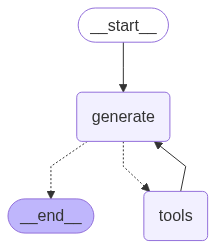

In [11]:
# 그래프 출력하기
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    pass

In [15]:
# 답변 출력하기
from langchain_core.messages import HumanMessage, AIMessageChunk

inputs = [HumanMessage(content="지금 서울 몇 시야?")]

gathered = None

for msg, metadata in graph.stream({"messages": inputs}, stream_mode="messages"):
    print(msg.content, end="")

    if isinstance(msg, AIMessageChunk):
        if gathered is None:
            gathered = msg
        else:
            gathered += gathered + msg

gathered


"\ud604\uc7ac \uc2dc\uac01: 2025-08-03 16:37:41 Asia/Seoul(\uc11c\uc6b8)"현재

KeyboardInterrupt: 

In [16]:
# 프롬프트 설정하고 기사 작성하기
from langchain_core.messages import AIMessageChunk, SystemMessage

about = "서울 월드컵 경기장 잔디 문제"

inputs = [SystemMessage(content=f"""
너는 신문기사이다.
최근 {about} 에 대해 비판하는 심층 분석 기사를 쓰려고 한다.

- 최근 어떤 이슈가 있는지 검색하고, 사람들이 제일 관심있어 할만한 주제를 선정하고, 왜 선정했는지 말 해줘.
- 그 내용으로 원고를 작성하기 위한 목차를 만들고, 목차 내용을 채우기 위해 추가로 검색할 내용을 리스트로 정리해봐.
- 검색할 리스트를 토대로 재검색해.
- 목차에 있는 내용을 작성하기 위해 더 검색이 필요한 정보가 있는지 확인하고, 있다면 추가로 검색해.
- 검색된 결과에 원하는 정보를 찾지 못했다면 다른 검색어로 재검색해도 좋아.

더 이상 검색할 내용이 없다면, 조선일보 신문 기사 형식으로 최종 기사를 작성한다.
제목, 부제, 리드문, 본문의 구성으로 작성한다. 본문 내용은 심층 분석 기사에 맞게 구체적이고 깊이 있게 작성해야 한다.
""")]

for msg, metadata in graph.stream({"messages": inputs}, stream_mode="messages"):
    if isinstance(msg, AIMessageChunk):
        print(msg.content, end="")


---------- WEB SEARCH ----------

검색 키워드: 서울 월드컵 경기장 잔디 문제
검색 기간: m


c:\workspace_test\llm_doit\.venv\Lib\site-packages\langchain_community\utilities\duckduckgo_search.py:63: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


1. snippet: 3 days ago · 잉글랜드 프리미어리그(epl) 뉴캐슬 유나이티드가 방한해 팀 k리그와 친선 경기를 치른 가운데 국내 축구장 '잔디 논란'이 또다시 고개를 들었다. 지난 30일 오후 경기 수원시 …, title: 선수도 "잔디 최악" 또 논란…4개월 만에 엉망 된 '빅버드', link: https://sports.news.nate.com/view/20250731n14679
2. snippet: 3 days ago · 수원월드컵경기장은 지난 3월, 재개장을 앞두고 서울월드컵경기장의 상태가 좋지 않다는 이유로 요르단과의 3차 예선 홈경기를 개최했다. 이에 따라 수원은 서울 이랜드와의 …, title: 팀 K리그, 뉴캐슬에 1-0 승리... 또 불거진 수원월드컵경기장 잔디 ..., link: https://star.ohmynews.com/NWS_Web/OhmyStar/at_pg.aspx?CNTN_CD=A0003152984
3. snippet: 3 days ago · 30일 2025 쿠팡플레이 시리즈 1차전 팀 k리그와 뉴캐슬 유나이티드 fc의 경기가 열린 수원월드컵경기장의 잔디 상태가 또다시 도마 위에 올랐다. 킥오프 1분도 되지 않아 하프라인 …, title: 한숨만 나오는 '빅버드 잔디"… "회복 불가능한 수준" | 세계일보, link: https://www.segye.com/newsView/20250731507295
4. snippet: 3 days ago · 수원월드컵경기장의 잔디 문제는 경기 주최를 요청한 측보다 일정을 고려하지 않고 무리하게 경기를 유치한 관리재단 측에 더 큰 아쉬움이 있다. 수원월드컵경기장 잔디 문제로 …, title: ‘7월 7경기’ 완전히 망가진 빅버드 잔디, ‘남의 집 잔치’에 ..., link: http://www.footballist.co.kr/news/articleView.html?idxno=199707
최근 서울 월드컵 경기장 잔디 문제에 대한 이슈가 부각되고 있습니다. 특히, 경기장 잔디의 상태가

c:\workspace_test\llm_doit\.venv\Lib\site-packages\langchain_community\utilities\duckduckgo_search.py:63: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:
c:\workspace_test\llm_doit\.venv\Lib\site-packages\langchain_community\utilities\duckduckgo_search.py:63: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


1. snippet: 동행·매력 특별시 서울의 주요뉴스, 시민참여, 주요서비스, 참여 신청, 행사 및 축제, 자주찾은서비스, 시장실, 분야별정보, 새소식, 서울영상, 서울소식, 서울녹서등의 정보제공, title: 서울특별시 - 동행·매력 특별시 서울, link: http://seoul.go.kr/
2. snippet: 서울특별시는 대한민국의 수도 [21]이자 최대 도시이다. 평양시, 경주시, 개성시, 공주시, 김해시, 부여군, 고령군, 함안군처럼 오랜 역사를 가진 대한민국의 고도 중 하나다. 법률상 대한민국 제 1의 도시로 규정되어 있다. [22], title: 서울특별시 - 나무위키, link: https://namu.wiki/w/서울특별시
3. snippet: 서울특별시(서울特別市, 영어: Seoul Metropolitan City)는 사실상 대한민국의 수도이자 문화·인문·정치·경제 중심지 역할을 하는 도시로, 경기도와 인천광역시까지 아우르는 수도권의 중심지 기능을 하고 있다., title: 서울특별시 - 위키백과, 우리 모두의 백과사전, link: https://ko.wikipedia.org/wiki/서울특별시
4. snippet: 서울 관광 명소. 놓칠 수 없는 서울의 숨은 명소! 랜드마크, 고궁, 역사적 장소, 오래된 가게들(오래가게), 미술관 & 박물관 모아보기., title: 서울 가볼만한 관광 명소 | 서울 공식 관광정보 웹사이트 - Seoul, link: https://korean.visitseoul.net/attractions

---------- WEB SEARCH ----------

검색 키워드: 선수 잔디 상태 반응
검색 기간: m
1. snippet: 선수등록 목록; 선수등록 이력조회; 2012~2021년 자료; 2005~2011년 자료; 선수통합검색, title: 스포츠지원포털 - 등록현황 - 선수 - 선수등록목록 - Sports, link: https://g1.sports.or.kr/stat/stat06.do
2. snippet:

c:\workspace_test\llm_doit\.venv\Lib\site-packages\langchain_community\utilities\duckduckgo_search.py:63: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


1. snippet: Jul 17, 2025 · 붕괴한 가장교차로 옹벽은 총길이가 330여m에 높이 10여m로, 시설물의 안전 및 유지 관리에 관한 특별법 상 제2종 시설물에 해당해, 사고의 원인이 관리 주체의 관리 소홀에서 비롯됐다는 점이 입증될 경우 중대시민재해 적용이 …, title: 오산 옹벽붕괴사고, 중대시민재해 적용되나…관리소홀 여부 ..., link: https://www.yna.co.kr/view/AKR20250717078000061
2. snippet: Jul 17, 2025 · 민원인 A 씨는 지난 15일 오전 7시 19분 안전신문고 앱을 통해 오산시 도로과에 " (사고가 난 도로의) 2차로 오른쪽 부분 지반이 침하하고 있고, 빗물 침투 시 붕괴가 우려된다"고 제보했습니다. 그는 "이 부분은 보강토로 …, title: 오산시 '붕괴 사고' 막을 기회 있었다…"신고 내용 대응 소홀", link: https://news.sbs.co.kr/news/endPage.do?news_id=N1008181738
3. snippet: 7 hours ago · 📌 실사례: “영유아용 액상 비타민이 터져 시트 교체가 필요했지만, 보험사는 ‘차량 고유 기능에 지장이 없고 관리 소홀’이라는 이유로 지급 거절” (출처: 소비자원 자동차 피해 사례집) 이러한 물품은 단순히 차에 두지 않는 것이 …, title: 이 물건들 뒀다간 보상 못 받습니다 – 차 안 보관금지 7선 - card ..., link: https://cardcarcare.com/차량-내-보관금지-물건-7가지/
4. snippet: Jul 17, 2025 · 17일 경찰 등에 따르면 전날 오후 7시4분쯤 오산시 가장동 가장교차로 고가도로의 옹벽 상단이 붕괴하면서 아래 도로를 지나던 40대 남성 운전자 1명이 숨지는 사고가 일어났다. 옹벽 파편이 순식간에 아래로 쏟아져 내리며 매몰된 …, title: 이권재 오산시장 '중대시민재해' 책임지나?…경찰, 옹벽 관리 ..., link: https://news.n

c:\workspace_test\llm_doit\.venv\Lib\site-packages\langchain_community\utilities\duckduckgo_search.py:63: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


1. snippet: Jul 22, 2025 · 기후 변화와 관련하여, 잔디결정은 대기 중의 이산화탄소를 흡수하여 온실가스를 줄이는 데 기여합니다 잔디는 광합성을 통해 대량의 이산화탄소를 고정하고, 이를 통해 지구 온난화를 완화하는 역할을 수행합니다, title: 잔디결정의 생태적 중요성 - 네이버 블로그, link: https://blog.naver.com/nature1774/223933451382
2. snippet: Jul 7, 2025 · 기후 변화가 심해지는 만큼, 이제는 ‘기후 대응형 잔디 관리’가 필수가 되고 있습니다. 정원의 작은 잔디밭부터 골프장의 페어웨이까지, 모두 건강한 녹색 여름 보내시길 바랍니다., title: 폭염 속 잔디 하고현상, 열돔 영향과 한지형 잔디 관리법 총정리, link: https://greenmaster-j.tistory.com/79
3. snippet: Jul 22, 2025 · 잔디가 고온에 시들해진다면, 회복은 가능할까?여름철 고온 스트레스는 잔디 생육에 큰 타격을 주며, 관리하지 않으면 광범위한 손상과 고사로 이어질 수 있습니다., title: 고온 스트레스로 인한 잔디 피해, 어떻게 대처해야 할까?, link: https://turf-lnside.tistory.com/entry/고온-스트레스로-인한-잔디-피해-어떻게-대처해야-할까
4. snippet: Jul 23, 2025 · 전 세계적으로 심화되고 있는 기후변화에 따라 골프장 코스 관리 분야가 직면한 도전과 변화에 대응하기 위한 자리였다., title: 한국잔디연구소, 기후 변화 대응 최신 기술과 전략 공유, link: https://www.asiae.co.kr/article/2025072319083249241

---------- WEB SEARCH ----------

검색 키워드: 잔디 문제 선수 부상 사례
검색 기간: m
1. snippet: 잔디소개. 기능; 보안; 회사소개; 채용; 고객사례; 요금안내; 도입문의; 리소스. 잔디 소개 자료; 협업툴 

c:\workspace_test\llm_doit\.venv\Lib\site-packages\langchain_community\utilities\duckduckgo_search.py:63: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:
c:\workspace_test\llm_doit\.venv\Lib\site-packages\langchain_community\utilities\duckduckgo_search.py:63: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


1. snippet: Jul 7, 2025 · 2025년 4~5월 두 달간 한국잔디연구소는 총 133회에 걸쳐 회원사 골프장을 방문, 기후대 및 초종에 따른 맞춤형 그린·페어웨이 관리방안, 라지패취병 등 병해 예방, 주요 조경수목 …, title: '골프장 핵심은 잔디 관리', 한국골프장경영협회 부설 한국잔디 ..., link: https://www.sportschosun.com/golf/2025-07-07/202507070100052370006905
2. snippet: Jul 23, 2025 · 잔디 품종, 병해 관리, 자동화 기술 등 다양한 주제를 다뤘다., title: 한국잔디연구소, 기후 변화 대응 최신 기술과 전략 공유, link: https://www.asiae.co.kr/article/2025072319083249241
3. snippet: Jul 25, 2025 · 바뀌는 한반도 기후에 대응한 골프장 잔디 관리의 다양한 방법들이 논의됐다. 한국골프장경영협회 부설 한국잔디연구소는 지난 18일 경기도 용인 골드CC 훼미리콘도 …, title: 한국골프장경영협회 잔디연구소, 골프장 관리 최신기술 공유, link: https://www.asiatoday.co.kr/kn/view.php?key=20250725010014708
4. snippet: Jul 7, 2025 · [스포츠서울 | 장강훈 기자] 사단법인 한국골프장경영협회가 한국잔디연구소의 활동 체계를 권역 거점 중심으로 개편했다. 권역별 밀착형 기술 자문을 제공하기 위해서다. 협회는 7일 …, title: 한국골프장경영협회, 기후대별 거점서 잔디 밀착 관리 나서, link: https://www.sportsseoul.com/news/read/1528849
### 추가 검색 결과 요약

1. **서울 월드컵 경기장 잔디 상태 보고서**: 서울시에서 제공하는 잔디 관리에 대한 정보와 최근 잔디 상태에 대한 보고서가 있습니다. [서울시 잔디 관리 정보](http://seoul.go.kr/)

2. **